# SEP-28k-Extended Download Audit

Audits the result of running `download_audio.py`: which podcast episodes were
successfully downloaded/converted to WAV, which are missing, why their source
URLs are dead, and how that ripples through to the labeled clip set in
`SEP-28k-Extended_clips.csv`.

Re-run this notebook any time after a download pass — it derives everything
from the current contents of `wavs/` plus a live check of each missing URL, so
it stays accurate as more episodes are retried/added.

In [1]:
import pathlib

import matplotlib.pyplot as plt
import pandas as pd
import requests
from tqdm.notebook import tqdm

WAVS_DIR = pathlib.Path('wavs')
EPISODES_CSV = 'SEP-28k-Extended_episodes.csv'
CLIPS_CSV = 'SEP-28k-Extended_clips.csv'

plt.rcParams['figure.figsize'] = (9, 5)

## 1. Which episodes downloaded successfully?

Ground truth is the presence of a converted `<EpId>.wav` file under
`wavs/<Show>/`. This is robust to re-runs: `download_audio.py` skips any
episode whose WAV already exists, so the directory always reflects the
cumulative successful set.

In [2]:
episodes = pd.read_csv(EPISODES_CSV)
episodes['url'] = episodes['url'].str.strip()
episodes['Show'] = episodes['Show'].str.strip()

def wav_exists(row):
    return (WAVS_DIR / row['Show'] / f"{row['EpId']}.wav").exists()

episodes['downloaded'] = episodes.apply(wav_exists, axis=1)

n_total = len(episodes)
n_ok = int(episodes['downloaded'].sum())
n_missing = n_total - n_ok
print(f"Episodes total:      {n_total}")
print(f"Downloaded (WAV ok): {n_ok}  ({n_ok / n_total:.1%})")
print(f"Missing:             {n_missing}  ({n_missing / n_total:.1%})")

Episodes total:      385
Downloaded (WAV ok): 258  (67.0%)
Missing:             127  (33.0%)


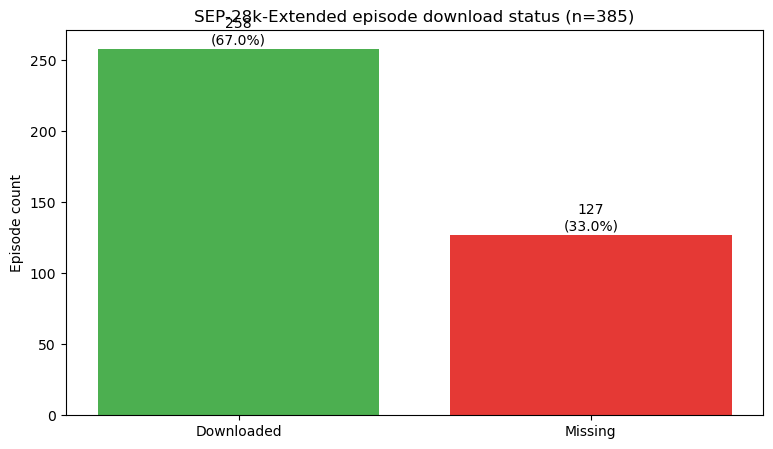

In [3]:
fig, ax = plt.subplots()
ax.bar(['Downloaded', 'Missing'], [n_ok, n_missing], color=['#4caf50', '#e53935'])
for i, v in enumerate([n_ok, n_missing]):
    ax.text(i, v + 3, f'{v}\n({v / n_total:.1%})', ha='center')
ax.set_ylabel('Episode count')
ax.set_title(f'SEP-28k-Extended episode download status (n={n_total})')
plt.show()

## 2. Which shows (podcasts) are most affected?

Some shows are hosted on domains that have gone offline entirely — those
shows will show 0% success, while others may have only a handful of dead
episode links.

In [4]:
by_show = (
    episodes.groupby('Show')['downloaded']
    .agg(total='count', downloaded='sum')
    .assign(missing=lambda d: d['total'] - d['downloaded'],
            pct_downloaded=lambda d: d['downloaded'] / d['total'])
    .sort_values('pct_downloaded')
)
by_show

,total,downloaded,missing,pct_downloaded
Show,,,,
IStutterSoWhat,5,0,5,0.00
StrongVoices,35,0,35,0.00
StutteringIsCool,85,0,85,0.00
MyStutteringLife,40,38,2,0.95
HVSA,4,4,0,1.00
HeStutters,24,24,0,1.00
StutterTalk,82,82,0,1.00
WomenWhoStutter,110,110,0,1.00


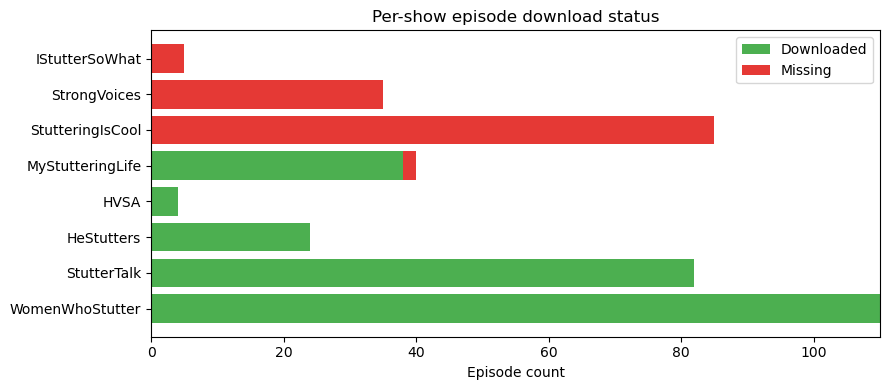

In [5]:
fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(by_show))))
y = range(len(by_show))
ax.barh(y, by_show['downloaded'], color='#4caf50', label='Downloaded')
ax.barh(y, by_show['missing'], left=by_show['downloaded'], color='#e53935', label='Missing')
ax.set_yticks(list(y))
ax.set_yticklabels(by_show.index)
ax.invert_yaxis()
ax.set_xlabel('Episode count')
ax.set_title('Per-show episode download status')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Why are the missing episodes' links dead?

Live-checks each missing episode's source URL with a short streamed `GET`
(closed immediately after the headers arrive) and classifies the failure:

- **DNS resolution failed** — the host no longer exists at all (site shut down)
- **HTTP 4xx (e.g. 404)** — host is up but the specific file/feed redirect is gone
- **HTTP 5xx** — host-side server error
- **Timeout / connection error** — host unreachable for other reasons
- **OK now** — the link actually works when re-checked (transient failure during
  the original run; re-running `download_audio.py` should pick it up)

This makes the audit reproducible — it doesn't depend on parsing the original
(ephemeral) download log.

In [6]:
def classify_url(url, timeout=15.0):
    """Why a download link fails today (or 'OK now' if it works)."""
    try:
        with requests.get(url, stream=True, timeout=timeout) as resp:
            if resp.ok:
                return 'OK now (transient failure earlier)'
            kind = 'client' if resp.status_code < 500 else 'server'
            return f'HTTP {resp.status_code} {kind} error'
    except requests.exceptions.ConnectionError as e:
        if 'NameResolutionError' in str(e):
            return 'DNS resolution failed'
        return 'Connection error'
    except requests.exceptions.Timeout:
        return 'Timeout'
    except requests.exceptions.RequestException:
        return 'Other request error'


missing = episodes[~episodes['downloaded']].copy()
missing['domain'] = missing['url'].str.extract(r'https?://([^/]+)/')

tqdm.pandas(desc='Checking dead links')
missing['failure_reason'] = missing['url'].progress_apply(classify_url)
missing[['Show', 'EpId', 'domain', 'failure_reason', 'url']].head(20)

Checking dead links:   0%|          | 0/127 [00:00<?, ?it/s]

,Show,EpId,domain,failure_reason,url
28,IStutterSoWhat,0,istuttersowhat.com,DNS resolution failed,http://istuttersowhat.com/podcast/ISSW007final...
29,IStutterSoWhat,1,istuttersowhat.com,DNS resolution failed,http://istuttersowhat.com/podcast/ISSWPodcast0...
30,IStutterSoWhat,2,istuttersowhat.com,DNS resolution failed,http://istuttersowhat.com/podcast/ISSWPodcast0...
31,IStutterSoWhat,3,istuttersowhat.com,DNS resolution failed,http://istuttersowhat.com/podcast/ISSWPodcast0...
32,IStutterSoWhat,4,istuttersowhat.com,DNS resolution failed,http://istuttersowhat.com/podcast/ISSWPodcast0...
55,MyStutteringLife,22,traffic.libsyn.com,HTTP 404 client error,https://traffic.libsyn.com/secure/mystuttering...
58,MyStutteringLife,25,traffic.libsyn.com,HTTP 404 client error,https://traffic.libsyn.com/secure/mystuttering...
73,StrongVoices,0,feeds.soundcloud.com,HTTP 404 client error,http://feeds.soundcloud.com/stream/393268140-u...
74,StrongVoices,1,feeds.soundcloud.com,HTTP 404 client error,http://feeds.soundcloud.com/stream/407179179-u...
75,StrongVoices,2,feeds.soundcloud.com,HTTP 404 client error,http://feeds.soundcloud.com/stream/413976822-u...


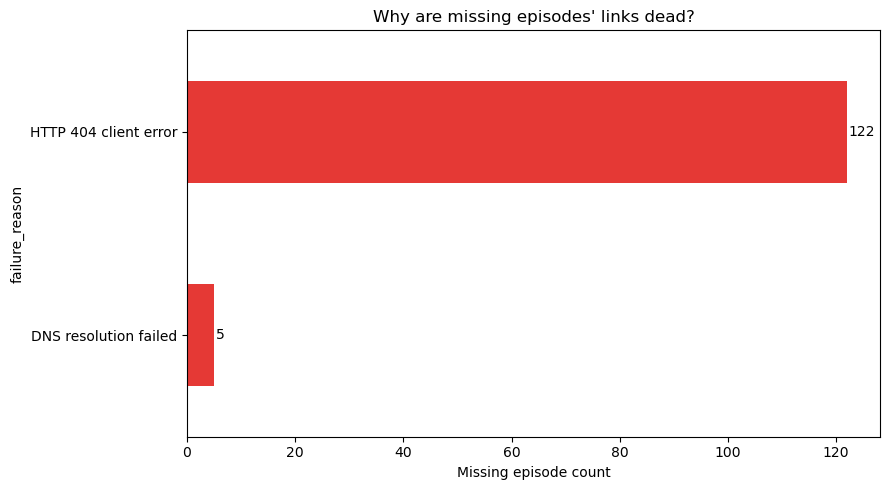

failure_reason
HTTP 404 client error    122
DNS resolution failed      5
Name: count, dtype: int64

In [7]:
reason_counts = missing['failure_reason'].value_counts()

fig, ax = plt.subplots()
reason_counts.plot.barh(ax=ax, color='#e53935')
ax.invert_yaxis()
ax.set_xlabel('Missing episode count')
ax.set_title('Why are missing episodes\' links dead?')
for i, v in enumerate(reason_counts.values):
    ax.text(v + 0.3, i, str(v), va='center')
plt.tight_layout()
plt.show()

reason_counts

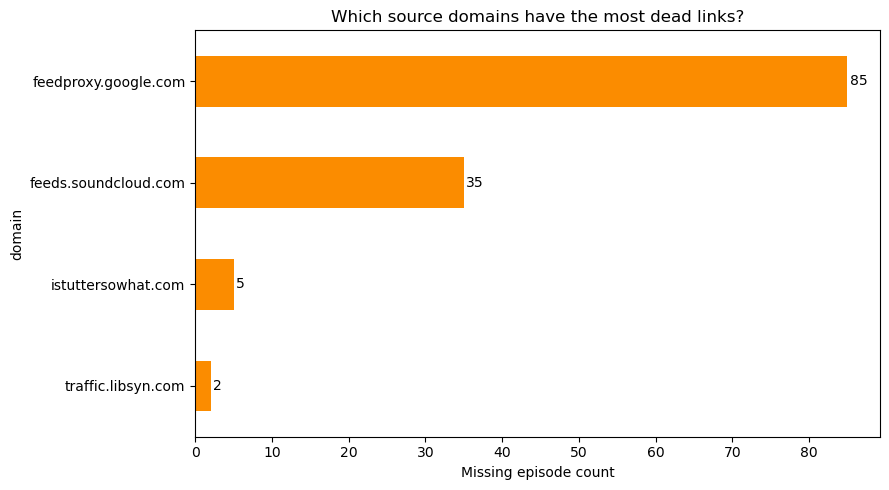

In [8]:
domain_counts = missing['domain'].value_counts().head(15)

fig, ax = plt.subplots()
domain_counts.plot.barh(ax=ax, color='#fb8c00')
ax.invert_yaxis()
ax.set_xlabel('Missing episode count')
ax.set_title('Which source domains have the most dead links?')
for i, v in enumerate(domain_counts.values):
    ax.text(v + 0.3, i, str(v), va='center')
plt.tight_layout()
plt.show()

## 4. Impact on the labeled clip set

`SEP-28k-Extended_clips.csv` references clips by `(Show, EpId)`. A missing
episode means every clip cut from it is unusable until that episode's audio is
obtained. This translates the episode-level gap into the actual
training-data impact.

In [9]:
clips = pd.read_csv(CLIPS_CSV)
clips['Show'] = clips['Show'].str.strip()

ep_status = episodes.set_index(['Show', 'EpId'])['downloaded']
clips['episode_downloaded'] = clips.set_index(['Show', 'EpId']).index.map(ep_status)

n_clips_total = len(clips)
n_clips_available = int(clips['episode_downloaded'].sum())
n_clips_missing = n_clips_total - n_clips_available

print(f"Labeled clips total:                {n_clips_total}")
print(f"Clips with audio available:         {n_clips_available}  ({n_clips_available / n_clips_total:.1%})")
print(f"Clips blocked by missing episodes:  {n_clips_missing}  ({n_clips_missing / n_clips_total:.1%})")

Labeled clips total:                28177
Clips with audio available:         20906  (74.2%)
Clips blocked by missing episodes:  7271  (25.8%)


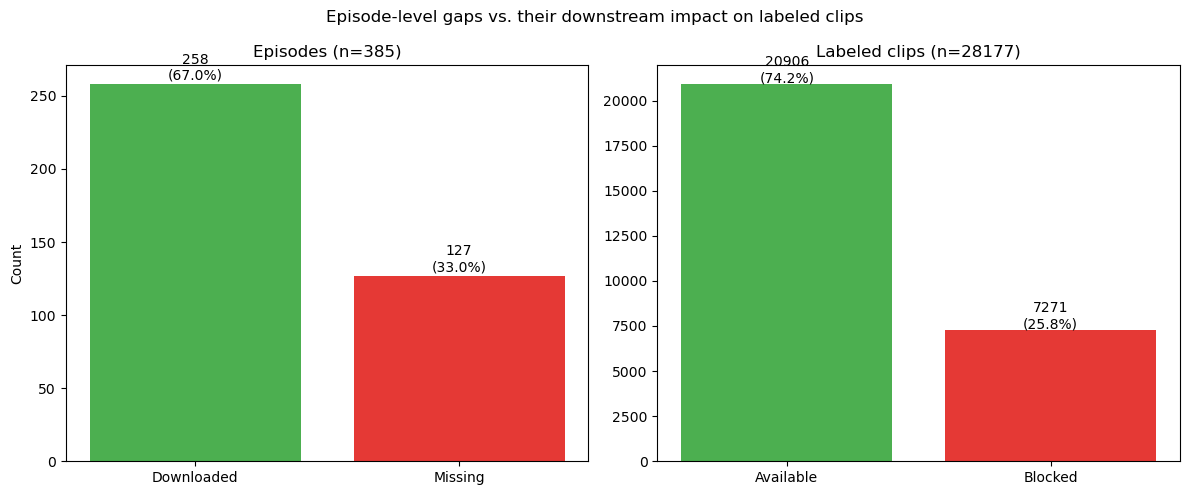

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(['Downloaded', 'Missing'], [n_ok, n_missing], color=['#4caf50', '#e53935'])
axes[0].set_title(f'Episodes (n={n_total})')
axes[0].set_ylabel('Count')
for i, v in enumerate([n_ok, n_missing]):
    axes[0].text(i, v + 3, f'{v}\n({v / n_total:.1%})', ha='center')

axes[1].bar(['Available', 'Blocked'], [n_clips_available, n_clips_missing], color=['#4caf50', '#e53935'])
axes[1].set_title(f'Labeled clips (n={n_clips_total})')
for i, v in enumerate([n_clips_available, n_clips_missing]):
    axes[1].text(i, v + 100, f'{v}\n({v / n_clips_total:.1%})', ha='center')

fig.suptitle('Episode-level gaps vs. their downstream impact on labeled clips')
plt.tight_layout()
plt.show()

## 5. Does the gap skew the label distribution?

Compares the proportion of clips carrying each stutter-type label in the
*available* set vs. the *full* labeled set. Large discrepancies would mean the
missing episodes aren't a random sample — e.g. if one show that's entirely
offline tends to have unusually high/low rates of a given disfluency type.

In [11]:
label_cols = ['Prolongation', 'Block', 'SoundRep', 'WordRep', 'Interjection', 'NoStutteredWords']

# A clip "has" a label when at least 2 of 3 annotators marked it (matches common SEP-28k convention)
has_label = clips[label_cols] >= 2

full_rates = has_label.mean()
available_rates = has_label[clips['episode_downloaded']].mean()

comparison = pd.DataFrame({'full_dataset': full_rates, 'available_only': available_rates})
comparison['abs_diff_pp'] = (comparison['available_only'] - comparison['full_dataset']) * 100
comparison

,full_dataset,available_only,abs_diff_pp
Prolongation,0.099798,0.097723,-0.207457
Block,0.119601,0.120970,0.136896
SoundRep,0.083117,0.088013,0.489557
WordRep,0.098307,0.111499,1.319196
Interjection,0.211981,0.226347,1.436510
NoStutteredWords,0.569472,0.551851,-1.762041


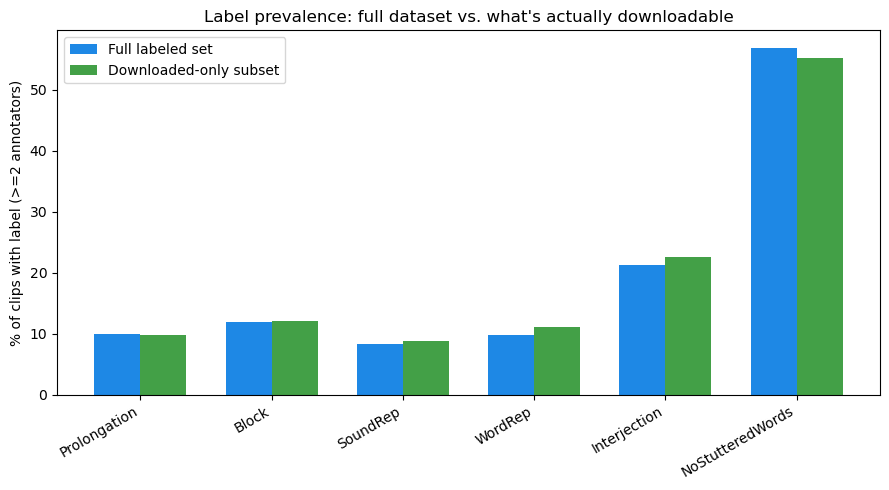

In [12]:
x = range(len(label_cols))
width = 0.35

fig, ax = plt.subplots()
ax.bar([i - width / 2 for i in x], comparison['full_dataset'] * 100, width, label='Full labeled set', color='#1e88e5')
ax.bar([i + width / 2 for i in x], comparison['available_only'] * 100, width, label='Downloaded-only subset', color='#43a047')
ax.set_xticks(list(x))
ax.set_xticklabels(label_cols, rotation=30, ha='right')
ax.set_ylabel('% of clips with label (>=2 annotators)')
ax.set_title('Label prevalence: full dataset vs. what\'s actually downloadable')
ax.legend()
plt.tight_layout()
plt.show()

## 6. How much of each class is missing?

For every stutter-type label, what fraction of the clips that carry that
label sit in episodes we don't have audio for? A class that's
disproportionately concentrated in the missing episodes is a bigger problem
than its overall share of the dataset would suggest — it directly limits how
many positive examples of that class you can actually train/evaluate on.

In [13]:
class_missing = pd.DataFrame({
    'clips_with_label': has_label[label_cols].sum(),
    'missing_clips_with_label': has_label[label_cols][~clips['episode_downloaded']].sum(),
})
class_missing['pct_of_class_missing'] = (
    class_missing['missing_clips_with_label'] / class_missing['clips_with_label'] * 100
)
class_missing = class_missing.sort_values('pct_of_class_missing', ascending=False)
class_missing

,clips_with_label,missing_clips_with_label,pct_of_class_missing
NoStutteredWords,16046,4509,28.100461
Prolongation,2812,769,27.347084
Block,3370,841,24.955490
SoundRep,2342,502,21.434671
Interjection,5973,1241,20.776829
WordRep,2770,439,15.848375


C:\Users\User\AppData\Local\Temp\ipykernel_748\3143149478.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(class_missing.index, rotation=30, ha='right')


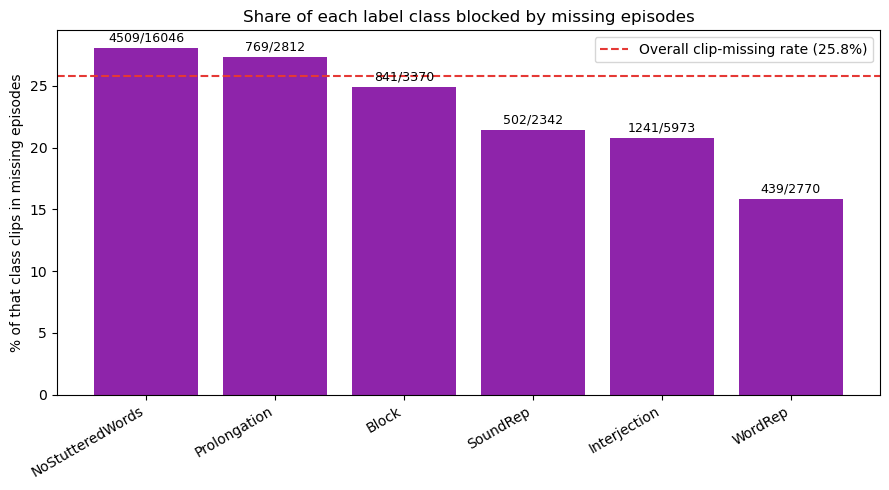

In [14]:
fig, ax = plt.subplots()
bars = ax.bar(class_missing.index, class_missing['pct_of_class_missing'], color='#8e24aa')
ax.axhline(n_clips_missing / n_clips_total * 100, color='#e53935', linestyle='--',
           label=f'Overall clip-missing rate ({n_clips_missing / n_clips_total:.1%})')
for bar, (count_missing, count_total) in zip(bars, zip(class_missing['missing_clips_with_label'],
                                                        class_missing['clips_with_label'])):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f'{count_missing}/{count_total}', ha='center', fontsize=9)
ax.set_xticklabels(class_missing.index, rotation=30, ha='right')
ax.set_ylabel('% of that class clips in missing episodes')
ax.set_title('Share of each label class blocked by missing episodes')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Export the missing-episode list

Useful for retrying later (e.g. checking the Internet Archive / Wayback
Machine for these URLs, or contacting show hosts directly).

In [15]:
out_path = 'missing_episodes.csv'
missing[['Show', 'EpId', 'domain', 'failure_reason', 'url']].sort_values(['Show', 'EpId']).to_csv(out_path, index=False)
print(f'Wrote {len(missing)} rows to {out_path}')

Wrote 127 rows to missing_episodes.csv
